# Where does the stress start, is it focal, is there repair, do neurons notice?

Four questions about the spatial structure of the oligodendrocyte (OL) stress response (prespecified gene sets,
`utils/gene_sets.py`; within-section, region-centred comparisons; responders vs controls by exact permutation,
84 relabellings, floor p = 0.012). Module: `utils/spatial_patterns.py`.

* **A. Borders.** Does OL stress fall with distance to the ventricles, the meningeal surface or vessels (outside-in,
  CSF / immune entry, as suggested by the IHC sites)?
* **B. Focal or diffuse?** Spatial correlogram of the *raw* per-cell ISR score (no smoothing, so clustering is not
  built in), region-centred: do neighbouring OLs share stress beyond the regional pattern?
* **C. Repair.** Are immature OLs (OPC-like I, pre-myelinating II, III) more numerous, proliferating or
  differentiating near stressed OLs?
* **D. Neurons.** Do neurons near stressed OLs show axonal-injury (regeneration-associated) or ISR genes?

In [1]:
import sys, itertools
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
REPO = Path.cwd().resolve().parent; sys.path.insert(0, str(REPO))
from utils import ol_staging as st, spatial_patterns as sp, neighbourhood as nbh
from utils.gene_sets import REPAIR_READOUTS, NEURON_READOUTS, IMMATURE_OL

OUT = REPO / "results" / "spatial_patterns"; FIG = OUT / "figures"; TAB = OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
sections = pd.read_csv(REPO / "results" / "sample_classifier" / "tables" / "sections_with_responder_calls.csv", index_col=0)
grp = sections["group"]; ctrl = sections.index[grp == "control"]; resp = sections.index[grp == "responder"]
cs = pd.read_csv(REPO / "results" / "cell_table" / "cell_gene_scores.csv.gz", index_col=0)
xy = pd.read_csv(REPO / "results" / "cell_table" / "cells.csv.gz", index_col=0, usecols=["cell_id", "x_centroid", "y_centroid"])
cs = cs.join(xy); cs = cs[cs.region != "Unknown"]
ols = cs[cs.cell_type == "Oligodendrocytes"].copy()
ols["slide_region"] = ols.sample_id.map(sections["age"]).astype(str) + "|" + ols.region
ols = st.smooth_scores(ols, ["ISR"], k=15)
ols["ISR_pct"] = st.control_percentile(ols, "ISR_smooth", ctrl, by="slide_region")
ols = ols.join(sp.border_distances(cs))

INK2, AXIS, GRID = "#52514e", "#c3c2b7", "#e1e0d9"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlelocation": "left"})
GROUP_ORDER = ["control", "non-responder", "responder"]
STYLE = {"control": dict(color=BLUE), "non-responder": dict(facecolor="white", edgecolor=ORANGE), "responder": dict(color=ORANGE)}
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight"); fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
def save_table(df, name, index=True):
    df.to_csv(TAB / f"{name}.csv", index=index); return df
def perm_p(values, a, b, alternative="greater"):
    v = values.loc[list(a) + list(b)].to_numpy(); na = len(a)
    obs = v[:na].mean() - v[na:].mean()
    null = np.array([v[list(c)].mean() - np.delete(v, list(c)).mean() for c in itertools.combinations(range(len(v)), na)])
    if alternative == "two-sided":
        return float(np.mean(np.abs(null) >= abs(obs) - 1e-12)), obs
    return float(np.mean(null >= obs - 1e-12)), obs
def dots(ax, values, title, ylab=None):
    for gi, g in enumerate(GROUP_ORDER):
        v = values[values.index.map(grp) == g].to_numpy()
        ax.scatter(np.full(len(v), gi) + np.linspace(-0.12, 0.12, len(v)), v, s=46, linewidth=1.4, zorder=3, **STYLE[g])
    ax.axhline(0, color=AXIS, lw=0.8); ax.set_xticks(range(3), ["ctrl", "non-resp", "resp"]); ax.set_xlim(-0.5, 2.5)
    ax.set_title(title, fontsize=9)
    if ylab: ax.set_ylabel(ylab)

## A. Distance to ventricles, meninges and vessels

,distance,r_control,r_responder,perm_p_two_sided
0,d_meninges,0.0205,0.0872,0.2500
1,d_ventricle,0.0419,0.1091,0.0952
2,d_vessel,-0.0447,-0.0756,0.0833


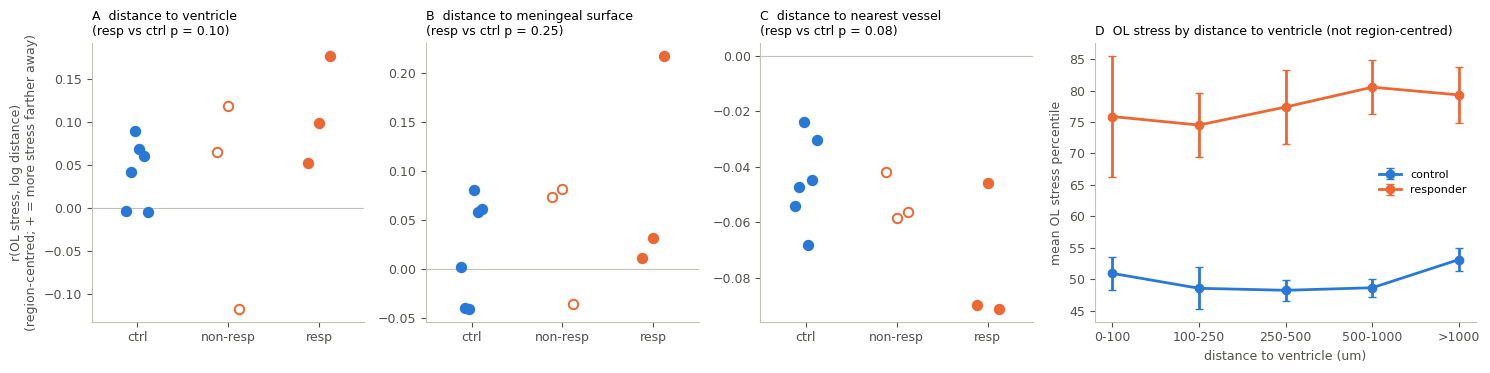

In [2]:
dc = sp.distance_coupling(ols, "ISR_smooth", ["d_ventricle", "d_meninges", "d_vessel"], grp)
save_table(dc.round(4), "border_coupling_per_section", index=False)
rows = []
for dist, d in dc.groupby("distance"):
    r = d.set_index("sample_id")["r"]
    p, diff = perm_p(r, resp, ctrl, "two-sided")
    rows.append({"distance": dist, "r_control": r.loc[ctrl].mean(), "r_responder": r.loc[resp].mean(), "perm_p_two_sided": p})
border = save_table(pd.DataFrame(rows).round(4), "border_coupling_summary", index=False)
display(border)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1, 1, 1, 1.4]})
for ax, (dist, lab) in zip(axes[:3], [("d_ventricle", "ventricle"), ("d_meninges", "meningeal surface"), ("d_vessel", "nearest vessel")]):
    r = dc[dc.distance == dist].set_index("sample_id")["r"]
    p = border.set_index("distance").loc[dist, "perm_p_two_sided"]
    dots(ax, r, f"{'ABC'[['d_ventricle','d_meninges','d_vessel'].index(dist)]}  distance to {lab}\n(resp vs ctrl p = {p:.2f})",
         "r(OL stress, log distance)\n(region-centred; + = more stress farther away)" if dist == "d_ventricle" else None)
ax = axes[3]
bins = [0, 100, 250, 500, 1000, 5000]
for g, col in [("control", BLUE), ("responder", ORANGE)]:
    d = ols[ols.sample_id.map(grp) == g].copy()
    d["b"] = pd.cut(d.d_ventricle, bins)
    m = d.groupby(["sample_id", "b"], observed=True)["ISR_pct"].mean().groupby("b", observed=True).agg(["mean", "sem"])
    ax.errorbar(range(len(m)), m["mean"], yerr=m["sem"], color=col, marker="o", lw=2, capsize=3, label=g)
ax.set_xticks(range(len(bins) - 1), ["0-100", "100-250", "250-500", "500-1000", ">1000"])
ax.set_xlabel("distance to ventricle (um)"); ax.set_ylabel("mean OL stress percentile"); ax.legend(frameon=False, fontsize=8)
ax.set_title("D  OL stress by distance to ventricle (not region-centred)", fontsize=9)
fig.tight_layout(); save(fig, "S1_border_distances")

**A.** Stress does not concentrate at the ventricles or meninges: within regions, responder OLs are if anything
*more* stressed farther from these borders (positive r). OLs near vessels are slightly more stressed in all groups
(baseline anatomy, not disease-specific). No support for an outside-in (CSF / meningeal) origin at 42 days.

## B. Focal patches or diffuse? Spatial correlogram of the raw per-cell ISR score

,band_um,r_control,r_responder,perm_p_two_sided
0,0-25,0.0474,0.0536,0.7143
1,25-50,0.0514,0.0563,0.7976
2,50-100,0.0552,0.0709,0.5000
3,100-200,0.0734,0.0716,0.8929
4,200-400,0.0345,0.0700,0.0833


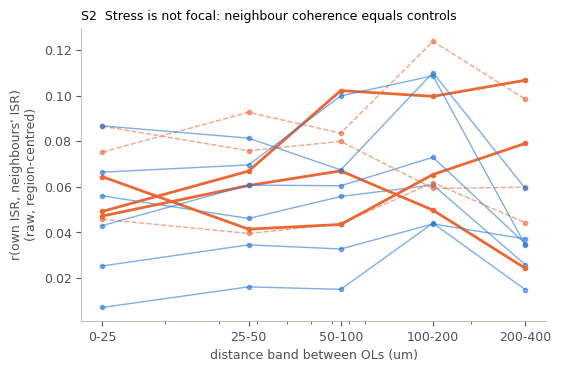

In [3]:
cg = sp.correlogram(ols, "ISR"); cg["group"] = cg.sample_id.map(grp)
save_table(cg.round(4), "isr_correlogram", index=False)
rows = []
for band, d in cg.groupby("band", sort=False):
    r = d.set_index("sample_id")["r"]
    p, diff = perm_p(r, resp, ctrl, "two-sided")
    rows.append({"band_um": band, "r_control": r.loc[ctrl].mean(), "r_responder": r.loc[resp].mean(), "perm_p_two_sided": p})
corr_summ = save_table(pd.DataFrame(rows).round(4), "isr_correlogram_summary", index=False)
display(corr_summ)
fig, ax = plt.subplots(figsize=(6, 3.8))
for sid, d in cg.groupby("sample_id"):
    g = grp[sid]; col = BLUE if g == "control" else ORANGE
    ax.plot(d.band_mid, d.r, color=col, lw=2 if g == "responder" else 1, ls="--" if g == "non-responder" else "-",
            alpha=1 if g == "responder" else 0.6, marker="o", ms=3)
ax.set_xscale("log"); ax.set_xticks([12.5, 37.5, 75, 150, 300], ["0-25", "25-50", "50-100", "100-200", "200-400"])
ax.set_xlabel("distance band between OLs (um)"); ax.set_ylabel("r(own ISR, neighbours' ISR)\n(raw, region-centred)")
ax.set_title("S2  Stress is not focal: neighbour coherence equals controls", fontsize=9)
save(fig, "S2_isr_correlogram")

**B.** Within a region, neighbouring OLs share stress no more in responders than in controls, at any distance from
0 to 400 um. Responder stress is a regional shift (thalamus, white matter) spread diffusely within regions, not
focal lesions. (A first patch analysis on smoothed scores was discarded: smoothing builds in clustering.)

## C. Repair: immature OLs near stressed OLs

,cell_type,readout,r_control,r_responder,perm_p,median_cells_per_section
0,Immature Oligodendrocytes I,NEWLY_FORMED_OL,0.0086,0.0196,0.2976,886
1,Immature Oligodendrocytes I,OPC,-0.0015,0.0031,0.3810,886
2,Immature Oligodendrocytes I,PROLIF,-0.0064,-0.0432,0.9643,886
3,Immature Oligodendrocytes II,NEWLY_FORMED_OL,-0.0132,0.1239,0.0714,169
4,Immature Oligodendrocytes II,OPC,-0.0197,0.0738,0.1429,169
5,Immature Oligodendrocytes II,PROLIF,0.0128,0.1036,0.0714,169


local immature-OL fraction vs OL stress: responders -0.007 vs controls 0.020, p = 0.976


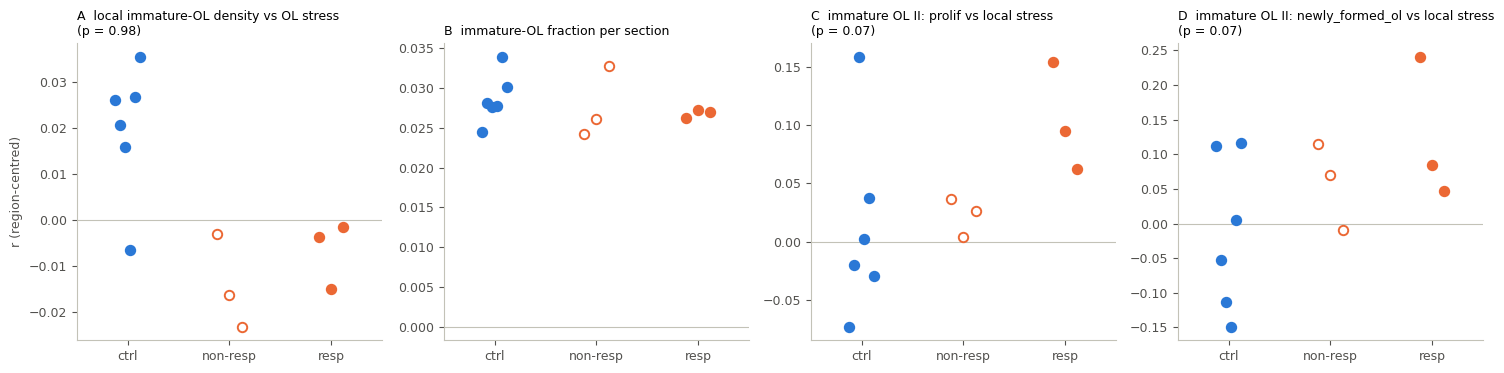

In [4]:
loc = nbh.local_ol_stress(cs, list(REPAIR_READOUTS), radius=50)
crep = nbh.coupling(loc, REPAIR_READOUTS, grp)
save_table(crep.round(4), "repair_coupling_per_section", index=False)
rows = []
for (ct, ro), d in crep.groupby(["cell_type", "readout"]):
    r = d.set_index("sample_id")["r"]
    if not set(resp) <= set(r.index) or not set(ctrl) <= set(r.index): continue
    p, diff = perm_p(r, resp, ctrl)
    rows.append({"cell_type": ct, "readout": ro, "r_control": r.loc[ctrl].mean(), "r_responder": r.loc[resp].mean(),
                 "perm_p": p, "median_cells_per_section": int(d.n_cells.median())})
rep = save_table(pd.DataFrame(rows).round(4), "repair_coupling_summary", index=False)
display(rep)
ols["frac_immature"] = sp.local_fraction(cs, ols, IMMATURE_OL, radius=50)
d = ols.dropna(subset=["frac_immature"])
cc = d[["ISR_smooth", "frac_immature"]] - d.groupby(["sample_id", "region"])[["ISR_smooth", "frac_immature"]].transform("mean")
dens = cc.groupby(d.sample_id).apply(lambda x: np.corrcoef(x.ISR_smooth, x.frac_immature)[0, 1])
pdens, _ = perm_p(dens, resp, ctrl)
imm_frac = cs.cell_type.isin(IMMATURE_OL).groupby(cs.sample_id).mean()
save_table(pd.DataFrame({"r_stress_vs_local_immature_fraction": dens, "section_immature_fraction": imm_frac}).join(grp).round(4), "repair_density")
print(f"local immature-OL fraction vs OL stress: responders {dens.loc[resp].mean():.3f} vs controls {dens.loc[ctrl].mean():.3f}, p = {pdens:.3f}")

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
dots(axes[0], dens, f"A  local immature-OL density vs OL stress\n(p = {pdens:.2f})", "r (region-centred)")
dots(axes[1], imm_frac, "B  immature-OL fraction per section")
for ax, ro, lab in [(axes[2], "PROLIF", "C"), (axes[3], "NEWLY_FORMED_OL", "D")]:
    r = crep[(crep.cell_type == "Immature Oligodendrocytes II") & (crep.readout == ro)].set_index("sample_id")["r"]
    p = rep[(rep.cell_type == "Immature Oligodendrocytes II") & (rep.readout == ro)]["perm_p"].iloc[0]
    dots(ax, r, f"{lab}  immature OL II: {ro.lower()} vs local stress\n(p = {p:.2f})")
fig.tight_layout(); save(fig, "S3_repair")

**C.** No overall repair response: immature OLs are neither more abundant near stressed OLs nor more abundant in
responder sections. Read the immature-OL II readouts with the permutation p in the table: they are few cells per
section, so any hint there is tentative.

## D. Neurons near stressed OLs

,cell_type,readout,r_control,r_responder,perm_p
0,Excitatory Neurons,AXON_INJURY,0.0004,-0.0051,0.6310
1,Excitatory Neurons,ISR,0.0127,0.0263,0.1786
2,GABAergic Neurons,AXON_INJURY,-0.0026,-0.0104,0.7024
3,GABAergic Neurons,ISR,0.0178,0.0422,0.1310
4,Medium Spiny Neurons,AXON_INJURY,-0.0027,-0.0260,0.8333
5,Medium Spiny Neurons,ISR,-0.0006,0.0117,0.1667
6,Neurons,AXON_INJURY,-0.0144,0.0410,0.0357
7,Neurons,ISR,0.0357,0.0347,0.5357


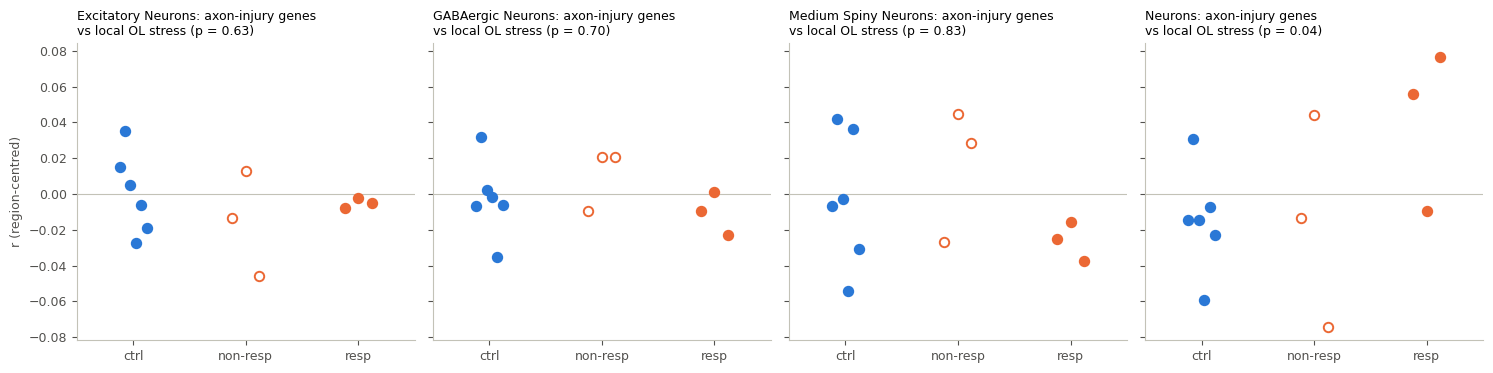

In [5]:
locn = nbh.local_ol_stress(cs, list(NEURON_READOUTS), radius=50)
cneu = nbh.coupling(locn, NEURON_READOUTS, grp)
save_table(cneu.round(4), "neuron_coupling_per_section", index=False)
rows = []
for (ct, ro), d in cneu.groupby(["cell_type", "readout"]):
    r = d.set_index("sample_id")["r"]
    p, diff = perm_p(r, resp, ctrl)
    rows.append({"cell_type": ct, "readout": ro, "r_control": r.loc[ctrl].mean(), "r_responder": r.loc[resp].mean(), "perm_p": p})
neu = save_table(pd.DataFrame(rows).round(4), "neuron_coupling_summary", index=False)
display(neu)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, ct in zip(axes, ["Excitatory Neurons", "GABAergic Neurons", "Medium Spiny Neurons", "Neurons"]):
    r = cneu[(cneu.cell_type == ct) & (cneu.readout == "AXON_INJURY")].set_index("sample_id")["r"]
    p = neu[(neu.cell_type == ct) & (neu.readout == "AXON_INJURY")]["perm_p"].iloc[0]
    dots(ax, r, f"{ct}: axon-injury genes\nvs local OL stress (p = {p:.2f})", "r (region-centred)" if ct == "Excitatory Neurons" else None)
fig.tight_layout(); save(fig, "S4_neurons")

**D.** No neuronal axonal-injury (regeneration-associated) or ISR response near stressed OLs at 42 days. Together
with C: the response is confined to OLs and their glial neighbours, with no detectable repair attempt or neuronal
damage yet, consistent with an early stage before the demyelination seen at 4-6 months.